# Práctica 4 - Anatomía de un dataset de Machine Learning
**Sesión 4 - El dataset**

## Objetivos
Analizar un dataset desde el punto de vista de Machine Learning: muestras, variables, identificadores, características, target, \(X\), \(y\), tipos conceptuales, valores ausentes y distribuciones.

> El objetivo principal no es escribir mucho código, sino **interpretar correctamente los datos**.

## Contexto
Una plataforma de comercio electrónico dispone de información histórica sobre sus clientes. Trabajaremos con `clientes_ecommerce.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador único |
| `edad` | Edad |
| `antiguedad_meses` | Meses desde el registro |
| `ingresos_anuales` | Ingresos anuales estimados |
| `gasto_mensual` | Gasto medio mensual |
| `num_compras` | Compras del último año |
| `devoluciones` | Devoluciones del último año |
| `dispositivo` | Dispositivo principal |
| `zona` | Zona de residencia |
| `nivel_fidelidad` | Bronce, Plata, Oro o Platino |
| `satisfaccion` | Valoración de 1 a 5 |
| `compra_proximo_mes` | Compra el mes siguiente: Sí/No |

Completa las celdas `# TODO` y responde en Markdown.

## Preparación

In [1]:
# TODO: importa NumPy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en df
df = pd.read_csv('clientes_ecommerce.csv')

## Parte 1 - Comprender el dataset
### Ejercicio 1 - Primera inspección
Muestra las primeras 10 filas.

In [2]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


### Respuesta
1. ¿Qué representa una fila?
2. ¿Qué representa una columna?
3. ¿Cuál es la unidad de observación?
4. ¿Todas las columnas son características? Justifica.

**Respuesta:**
1. Cada fila representa un registro individual correspondiente a un cliente de la plataforma.
2. Cada columna representa una variable o atributo medido sobre los clientes (zona, gastos_mensuales, ingresos, satisfacción, etc.).
3. La unidad de observación es si el cliente **compra el proximo mes o no**.
4. No. La columna "cliente_id" es un mero identificador único sin valor predictivo, y la columna "compra_proximo_mes" es la variable objetivo (*target*) que queremos predecir, no una característica de entrada (*feature*).

### Ejercicio 2 - Dimensiones
Obtén `df.shape`.

In [3]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

### Respuesta
- Número de muestras: 400
- Número de columnas: 12
- ¿Tenemos el mismo número de características? ¿Por qué?

No, tenemos 12 columnas en total, pero únicamente **10 características (*features*)** candidatas, ya que `cliente_id` actúa exclusivamente como identificador y `compra_proximo_mes` cumple el rol de variable objetivo (*target*).

## Parte 2 - Clasificación de variables
### Ejercicio 3 - Tipos almacenados

In [4]:
# TODO: consulta df.dtypes
df.dtypes

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object

### Ficha de variables
Clasifica cada variable como: **Identificador, Numérica discreta, Numérica continua, Categórica nominal, Categórica ordinal o Target**.

| Variable | dtype | Tipo conceptual | ¿Feature candidata? |
|---|---|---|---|
| cliente_id | int64 | Identificador | No |
| edad | int64 | Numérica discreta | Sí |
| antiguedad_meses | float64 | Numérica discreta | Sí |
| ingresos_anuales | float64 | Numérica continua | Sí |
| gasto_mensual | float64 | Numérica continua | Sí |
| num_compras | int64 | Numérica discreta | Sí |
| devoluciones | int64 | Numérica discreta | Sí |
| dispositivo | object / str | Categórica nominal | Sí |
| zona | object / str | Categórica nominal | Sí |
| nivel_fidelidad | object / str | Categórica ordinal | Sí |
| satisfaccion | int64 | Categórica ordinal | Sí |
| compra_proximo_mes | object / str | Target | No (es el target) |

No clasifiques únicamente por `dtype`.

### Ejercicio 4 - `cliente_id`
Muestra sus primeros 10 valores.

In [5]:
# TODO: analiza cliente_id
df['cliente_id'].head(10)

0    20001
1    20002
2    20003
3    20004
4    20005
5    20006
6    20007
7    20008
8    20009
9    20010
Name: cliente_id, dtype: int64

### Respuesta
1. ¿Qué dtype tiene?
2. ¿Es por ello cuantitativa?
3. ¿Tiene sentido calcular su media?
4. ¿La incluirías inicialmente en \(X\)?
5. Justifica.

**Respuesta:**
1. Tiene tipo técnico entero (`int64`).
2. No, el hecho de almacenarse con numeros no la convierte en una variable cuantitativa; es un código identificador arbitrario.
3. No tiene ningún sentido estadístico.
4. No, nunca debe incluirse en la matriz de características \(X\).
5. Si incluimos un identificador único en \(X\), el modelo puede memorizar registros concretos (sobreajuste o *overfitting*) en lugar de aprender patrones reales y generalizables sobre el comportamiento de los clientes.

### Ejercicio 5 - `satisfaccion`
Muestra la frecuencia de sus valores ordenados.

In [6]:
# TODO: value_counts() + sort_index()
df['satisfaccion'].value_counts().sort_index()

satisfaccion
1     33
2     58
3    123
4    116
5     70
Name: count, dtype: int64

Sabemos que 1 = Muy insatisfecho, 2 = Insatisfecho, 3 = Neutral, 4 = Satisfecho y 5 = Muy satisfecho.

### Respuesta
1. ¿Cómo la almacena pandas?
2. ¿Es simplemente numérica?
3. ¿Existe un orden?
4. ¿Nominal u ordinal?
5. Explica `dtype` frente a significado conceptual.

**Respuesta:**
1. Pandas la almacena como un entero (`int64`).
2. No es una variable puramente numérica continua ni de conteo, sino una escala de valoración codificada con números.
3. Sí, existe una jerarquía clara desde el grado menor (1 = Muy insatisfecho) hasta el mayor (5 = Muy satisfecho).
4. Es una variable **categórica ordinal**.
5. El `dtype` (`int64`) solo refleja cómo el ordenador guarda el dato en memoria, mientras que el significado conceptual depende de qué representa en la realidad: en este caso categorías ordenadas, donde la distancia subjetiva entre niveles no es necesariamente idéntica aunque se usen números enteros.

## Parte 3 - Calidad de los datos
### Ejercicio 6 - Información estructural

In [7]:
# TODO: utiliza df.info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Respuesta
1. ¿Cuántas muestras hay?
2. ¿Qué tipos técnicos aparecen?
3. ¿Todas las columnas tienen los mismos valores no nulos?
4. ¿Qué columnas contienen ausentes?
5. ¿Cuántos faltan?

**Respuesta:**
1. Hay **400** muestras (índices de 0 a 399).
2. Aparecen tres tipos técnicos: enteros (`int64` en 5 columnas), decimales (`float64` en 3 columnas) y texto/cadenas (`object` / `str` en 4 columnas).
3. No, hay tres columnas que tienen menos de 400 valores no nulos.
4. Contienen valores ausentes: `antiguedad_meses`, `ingresos_anuales` y `gasto_mensual`.
5. Faltan **5** valores en `antiguedad_meses` (395 no nulos), **4** en `ingresos_anuales` (396 no nulos) y **3** en `gasto_mensual` (397 no nulos), sumando un total de 12 celdas vacías.

### Ejercicio 7 - Valores ausentes
Calcula cantidad y porcentaje por columna.

In [8]:
# TODO: valores ausentes por columna
ausentes = df.isnull().sum()
print("Valores ausentes por columna:\n", ausentes)

# TODO: porcentaje de ausentes por columna
porcentaje_ausentes = (df.isnull().mean() * 100).round(2)
print("\nPorcentaje de ausentes (%):\n", porcentaje_ausentes)

Valores ausentes por columna:
 cliente_id            0
edad                  0
antiguedad_meses      5
ingresos_anuales      4
gasto_mensual         3
num_compras           0
devoluciones          0
dispositivo           0
zona                  0
nivel_fidelidad       0
satisfaccion          0
compra_proximo_mes    0
dtype: int64

Porcentaje de ausentes (%):
 cliente_id            0.00
edad                  0.00
antiguedad_meses      1.25
ingresos_anuales      1.00
gasto_mensual         0.75
num_compras           0.00
devoluciones          0.00
dispositivo           0.00
zona                  0.00
nivel_fidelidad       0.00
satisfaccion          0.00
compra_proximo_mes    0.00
dtype: float64


### Reflexión
¿Es lo mismo que falten 5 valores entre 50 muestras que entre 100.000? ¿Por qué son útiles los porcentajes?

No es en absoluto lo mismo. Que falten 5 valores en 50 muestras supone perder el **10 %** de la información de esa columna, un impacto relevante que puede sesgar el análisis si no se trata adecuadamente; en cambio, 5 valores en 100.000 muestras representan apenas el **0,005 %**, una proporción insignificante. Los porcentajes son esenciales porque relativizan el problema respecto al tamaño total del dataset y permiten comparar la gravedad de los datos faltantes entre datasets de distinto volumen.

## Parte 4 - Construcción de X e y
Queremos predecir: **¿realizará el cliente una compra el próximo mes?**

### Ejercicio 8 - Variable objetivo

In [9]:
# TODO: crea y
y = df['compra_proximo_mes']

# TODO: muestra y.head() y y.shape
print(y.head())
print("Shape de y:", y.shape)

0    No
1    No
2    Sí
3    Sí
4    No
Name: compra_proximo_mes, dtype: str
Shape de y: (400,)


### Respuesta
1. ¿Qué representa cada elemento de \(y\)?
2. ¿Cuántos contiene?
3. ¿Por qué el target no debe incluirse también en \(X\)?

**Respuesta:**
1. Cada elemento de \(y\) representa la etiqueta real o respuesta conocida de un cliente concreto indicando si realizará (`Sí`) o no (`No`) una compra el mes siguiente.
2. Contiene **400** elementos (uno por cada muestra del dataset).
3. Porque si incluimos la respuesta correcta dentro de las variables de entrada \(X\), estaríamos provocando fuga de datos (*data leakage*): el modelo aprendería simplemente a copiar esa columna y obtendría un rendimiento perfecto pero falso, siendo completamente inútil al predecir sobre clientes nuevos donde dicha columna no existe.

### Ejercicio 9 - Construir \(X\)
Usa: `edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad`, `satisfaccion`.

No incluyas `cliente_id` ni `compra_proximo_mes`.

In [10]:
# TODO: crea X
features = [
    'edad', 'antiguedad_meses', 'ingresos_anuales', 'gasto_mensual',
    'num_compras', 'devoluciones', 'dispositivo', 'zona',
    'nivel_fidelidad', 'satisfaccion'
]
X = df[features]

# TODO: muestra X.head() y X.shape
print(X.head())
print("Shape de X:", X.shape)

   edad  antiguedad_meses  ingresos_anuales  gasto_mensual  num_compras  \
0    67             102.0           9000.00          60.73            7   
1    28              93.0          35683.86         131.74            6   
2    19              87.0          37152.19          55.33            8   
3    55              79.0          40158.29          24.33            7   
4    39               3.0          27317.06          88.78            5   

   devoluciones dispositivo   zona nivel_fidelidad  satisfaccion  
0             3       Móvil  Oeste             Oro             5  
1             1       Móvil   Este          Bronce             2  
2             1   Ordenador   Este           Plata             5  
3             0   Ordenador  Norte          Bronce             4  
4             0       Móvil    Sur          Bronce             4  
Shape de X: (400, 10)


### Ejercicio 10 - Dimensiones
Completa y explica:

- \(n = 400\) (número total de muestras u observaciones, es decir, clientes registrados en el dataset).
- \(p = 10\) (número de características o variables predictoras seleccionadas para alimentar al modelo, excluyendo el identificador y el target).
- \(X.shape = (400, 10)\) (matriz bidimensional con 400 filas y 10 columnas).
- \(y.shape = (400,)\) (vector unidimensional con las 400 etiquetas objetivo correspondientes a cada fila de \(X\)).

## Parte 5 - ¿Está etiquetado?
### Ejercicio 11
1. ¿Tenemos \(X\)?
2. ¿Tenemos \(y\)?
3. ¿Está etiquetado?
4. ¿Puede usarse para aprendizaje supervisado?
5. ¿Qué tipo de problema es predecir `compra_proximo_mes`?
6. ¿Binario o multiclase?
7. ¿Cuáles son las clases?

**Respuesta:**
1. Sí, disponemos de la matriz de características \(X\) con 10 variables por cliente.
2. Sí, contamos con el vector objetivo \(y\) (`compra_proximo_mes`).
3. Sí, es un dataset **etiquetado**, ya que conocemos el resultado histórico real para cada observación.
4. Sí, al tener pares entrada-salida \((X, y)\) es totalmente apto para entrenar algoritmos de **aprendizaje supervisado**.
5. Es un problema de **clasificación**, puesto que la variable a predecir es categórica y discreta.
6. Es una clasificación **binaria**, dado que solo existen dos resultados posibles mutuamente excluyentes.
7. Las dos clases son **`Sí`** (el cliente compra el mes siguiente) y **`No`** (el cliente no compra el mes siguiente).

## Parte 6 - Distribuciones
### Ejercicio 12 - Variables categóricas
Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes` con frecuencias absolutas y relativas.

In [11]:
# TODO: value_counts() y value_counts(normalize=True) para las cuatro variables
categoricas = ['dispositivo', 'zona', 'nivel_fidelidad', 'compra_proximo_mes']

for col in categoricas:
    print(f"=== {col.upper()} ===")
    abs_freq = df[col].value_counts()
    rel_freq = (df[col].value_counts(normalize=True) * 100).round(2)
    resumen = pd.DataFrame({'Frecuencia': abs_freq, 'Porcentaje (%)': rel_freq})
    print(resumen, "\n")

=== DISPOSITIVO ===
             Frecuencia  Porcentaje (%)
dispositivo                            
Móvil               242           60.50
Ordenador           133           33.25
Tablet               25            6.25 

=== ZONA ===
        Frecuencia  Porcentaje (%)
zona                              
Este            89           22.25
Sur             80           20.00
Norte           79           19.75
Oeste           76           19.00
Centro          76           19.00 

=== NIVEL_FIDELIDAD ===
                 Frecuencia  Porcentaje (%)
nivel_fidelidad                            
Bronce                  162           40.50
Plata                   105           26.25
Oro                      83           20.75
Platino                  50           12.50 

=== COMPRA_PROXIMO_MES ===
                    Frecuencia  Porcentaje (%)
compra_proximo_mes                            
No                         246            61.5
Sí                         154            38.5 



### Tabla resumen
| Variable | Categoría más frecuente | Frecuencia | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.50 % |
| zona | Este | 89 | 22.25 % |
| nivel_fidelidad | Bronce | 162 | 40.50 % |
| compra_proximo_mes | No | 246 | 61.50 % |

### Ejercicio 13 - Visualización del target
Crea un gráfico de barras con título y etiquetas.

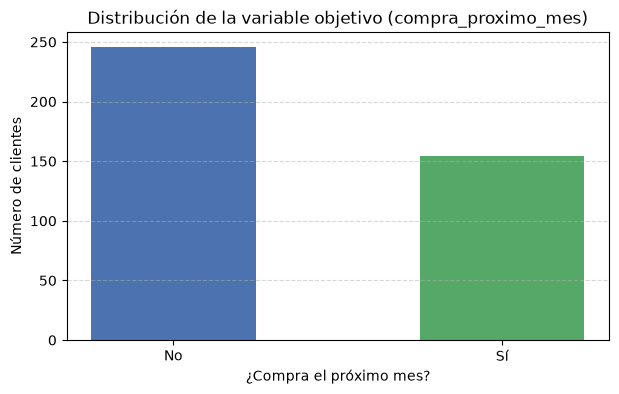

In [12]:
# TODO: gráfico de barras
conteos_target = df['compra_proximo_mes'].value_counts()

plt.figure(figsize=(7, 4))
plt.bar(conteos_target.index, conteos_target.values, color=['#4C72B0', '#55A868'], width=0.5)
plt.title('Distribución de la variable objetivo (compra_proximo_mes)')
plt.xlabel('¿Compra el próximo mes?')
plt.ylabel('Número de clientes')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### Interpretación
¿Las clases aparecen aproximadamente con la misma frecuencia? Justifica con datos.

No, las clases no están perfectamente equilibradas, aunque tampoco presentan un desbalanceo extremo. La clase mayoritaria es **`No`** con **246 clientes (61,50 %)**, mientras que la clase **`Sí`** cuenta con **154 clientes (38,50 %)**. Existe una diferencia de 23 puntos porcentuales (92 clientes más en el grupo que no compra), algo que conviene tener en cuenta al evaluar futuros modelos de clasificación.

## Parte 7 - Variables numéricas
### Ejercicio 14 - Estadística descriptiva
Analiza `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones`.

In [13]:
# TODO: describe() solo sobre las columnas indicadas
cols_num = ['edad', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones']
df[cols_num].describe()

,edad,ingresos_anuales,gasto_mensual,num_compras,devoluciones
count,400.000000,396.000000,397.000000,400.000000,400.000000
mean,46.402500,36440.920379,69.089320,8.225000,1.225000
std,18.007809,14325.228166,39.023238,2.780955,1.136929
min,18.000000,9000.000000,5.770000,2.000000,0.000000
25%,33.000000,26034.092500,39.720000,6.000000,0.000000
50%,45.000000,36817.275000,61.170000,8.000000,1.000000
75%,59.000000,45969.032500,90.150000,10.000000,2.000000
max,195.000000,82925.370000,260.000000,17.000000,5.000000


### Interpretación
Escribe una conclusión breve para cada variable:
- **edad:** La mayoría de clientes se concentra en edades adultas estándar (con mínimo en 18 años), pero el máximo alcanza los **195 años**, lo cual distorsiona la media hacia arriba y revela un claro dato anómalo.
- **ingresos_anuales:** Presenta una distribución bastante centrada en torno a los 36.400 € de media (mediana cercana a 36.850 €), con valores razonables que oscilan desde los 9.000 € hasta algo más de 70.000 €, y cuenta con 4 valores ausentes.
- **gasto_mensual:** Tiene una media de 69,09 € superior a su mediana de 61,17 € (y un máximo de 260 € frente a un mínimo de 5,77 €), lo que indica una asimetría positiva con una cola hacia clientes que gastan bastante más que la mayoría; además presenta 3 valores nulos.
- **num_compras:** Es una variable discreta de conteo sin valores nulos, donde los clientes realizan habitualmente varios pedidos al año concentrados en rangos moderados y con poca dispersión extrema.
- **devoluciones:** Muestra valores enteros bajos (partiendo desde 0 devoluciones en gran parte de los usuarios), reflejando que la mayoría de clientes apenas devuelve productos o realiza muy pocas devoluciones al año.

### Ejercicio 15 - Detectar algo sospechoso
1. ¿Hay algún valor poco razonable?
2. ¿En qué variable?
3. ¿Por qué es sospechoso?
4. ¿Lo eliminarías inmediatamente?
5. ¿Qué comprobarías antes?

**Respuesta:**
1. Sí, existe un valor completamente fuera de toda lógica biológica.
2. En la variable **`edad`** (concretamente en el registro con `cliente_id = 20138`).
3. Aparece una edad de **195 años**, una cifra imposible para una persona real, lo que apunta claramente a un error de introducción de datos o de transcripción.
4. No lo eliminaría de forma automática e inmediata sin analizarlo primero, porque al borrar toda la fila perderíamos información válida del resto de columnas de ese cliente (como su gasto, compras o fidelidad).
5. Antes de decidir si eliminar la fila o imputar el dato como nulo (`NaN`), comprobaría si es un caso aislado o hay más registros erróneos, revisaría si los demás atributos del cliente son coherentes y consultaría la fuente original de recogida de datos por si pudiera tratarse de un error tipográfico evidente (por ejemplo, haber tecleado `195` en lugar de `19` o `95`).

## Parte 8 - Distribuciones numéricas
### Ejercicio 16
Crea histogramas independientes de `edad`, `ingresos_anuales`, `gasto_mensual` y `num_compras`.

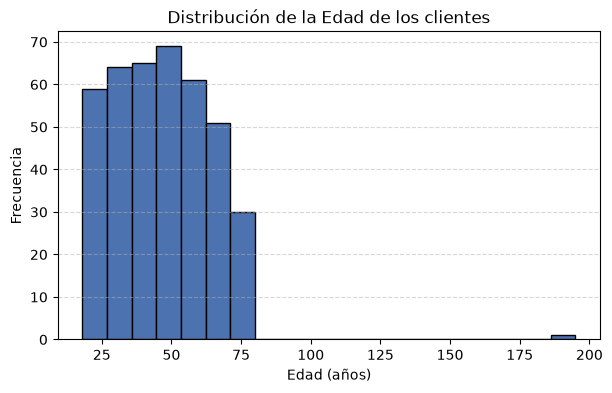

In [14]:
# TODO: histograma de edad
plt.figure(figsize=(7, 4))
plt.hist(df['edad'].dropna(), bins=20, color='#4C72B0', edgecolor='black')
plt.title('Distribución de la Edad de los clientes')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

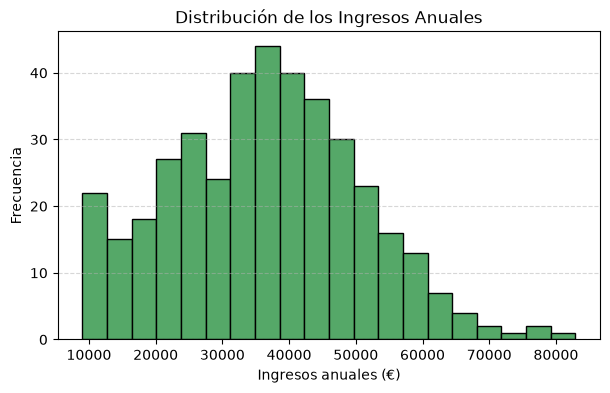

In [20]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(7, 4))
plt.hist(df['ingresos_anuales'].dropna(), bins=20, color='#55A868', edgecolor='black')
plt.title('Distribución de los Ingresos Anuales')
plt.xlabel('Ingresos anuales (€)')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

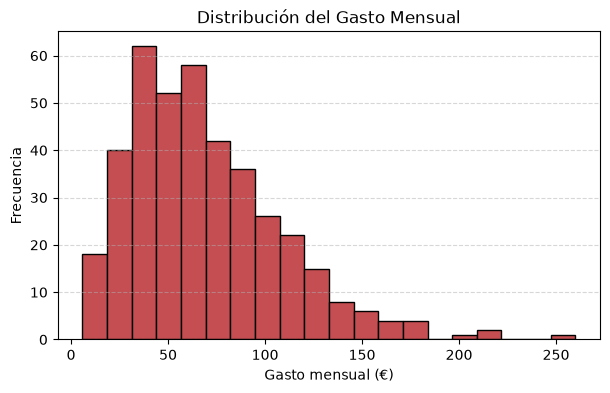

In [16]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(7, 4))
plt.hist(df['gasto_mensual'].dropna(), bins=20, color='#C44E52', edgecolor='black')
plt.title('Distribución del Gasto Mensual')
plt.xlabel('Gasto mensual (€)')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

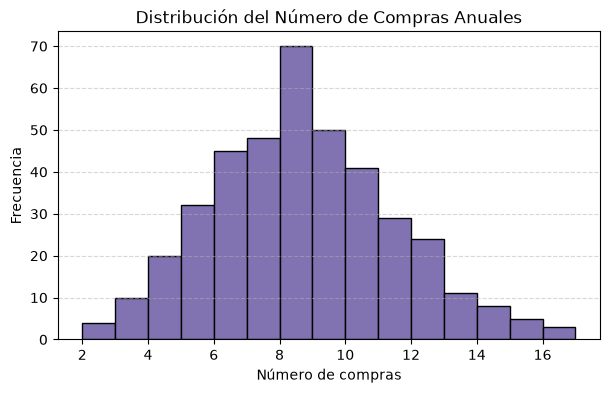

In [17]:
# TODO: histograma de num_compras
plt.figure(figsize=(7, 4))
plt.hist(df['num_compras'].dropna(), bins=15, color='#8172B2', edgecolor='black')
plt.title('Distribución del Número de Compras Anuales')
plt.xlabel('Número de compras')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### Observaciones
- **edad:** La gran mayoría de los clientes se reparte de forma bastante uniforme entre los 18 y los 75-80 años, pero el eje horizontal se estira artificialmente hasta casi 200 debido al valor anómalo aislado de 195 años.
- **ingresos_anuales:** Presenta una forma aproximadamente simétrica (acampanada), con la mayor concentración de clientes en la franja intermedia entre 25.000 € y 50.000 € anuales.
- **gasto_mensual:** Muestra una clara asimetría hacia la derecha (sesgo positivo): la mayoría de clientes gasta entre 25 € y 80 € al mes, mientras que existe una cola alargada hacia gastos altos (por encima de 160 € hasta 260 €).
- **num_compras:** Tiene una distribución concentrada en valores enteros moderados (en torno a 6-12 compras anuales), sin colas extremas ni valores atípicos llamativos.

## Parte 9 - Un mismo dataset, diferentes problemas
### Ejercicio 17 - Problema A
> ¿Realizará el cliente una compra el próximo mes?

Completa y justifica:
- Target: `compra_proximo_mes` (es la variable que recoge exactamente el evento futuro que deseamos predecir).
- ¿Existe \(y\)?: Sí, está presente en el dataset como una columna etiquetada con valores `Sí` y `No`.
- Supervisado / no supervisado: **Aprendizaje supervisado**, porque contamos con ejemplos históricos donde conocemos tanto las características del cliente como el resultado real.
- Clasificación / regresión / clustering: **Clasificación**, ya que la salida esperada es una categoría discreta y no una magnitud numérica continua.
- Binaria / multiclase: **Clasificación binaria**, puesto que solo existen dos clases posibles (`Sí` o `No`).

### Ejercicio 18 - Problema B
Supón una columna `gasto_proximo_mes` con cantidades monetarias.

> ¿Cuánto gastará el cliente el próximo mes?

1. ¿Cuál sería \(y\)?
2. ¿Qué tipo de variable?
3. ¿Supervisado?
4. ¿Clasificación o regresión?
5. ¿Por qué?

**Respuesta:**
1. La variable objetivo \(y\) sería la columna `gasto_proximo_mes`.
2. Sería una variable **numérica continua** (magnitud monetaria en euros).
3. Sí, seguiría siendo un problema de **aprendizaje supervisado** al disponer de los importes reales gastados como etiquetas de entrenamiento.
4. Sería un problema de **regresión**.
5. Porque el modelo debe estimar un valor numérico continuo (una cantidad de dinero) en lugar de asignar una categoría cerrada.

### Ejercicio 19 - Problema C
> Descubrir grupos de clientes similares sin grupos definidos previamente.

1. ¿Existe etiqueta de grupo?
2. ¿Necesitamos \(y\)?
3. ¿Supervisado o no supervisado?
4. ¿Qué técnica usaríamos?
5. ¿Qué variables podrían describir los grupos?

**Respuesta:**
1. No, no existe ninguna etiqueta predefinida que indique a qué segmento pertenece cada cliente.
2. No necesitamos vector objetivo \(y\), trabajamos únicamente con la matriz de características \(X\).
3. Es un problema de **aprendizaje no supervisado**.
4. Utilizaríamos técnicas de **clustering** (agrupamiento), como por ejemplo *K-Means* o clustering jerárquico.
5. Podrían describirse mediante variables de comportamiento y perfil como `gasto_mensual`, `num_compras`, `ingresos_anuales`, `antiguedad_meses`, `devoluciones` o `edad`.

## Parte 10 - Razonamiento
### Ejercicio 20 - ¿Una columna puede cambiar de papel?
¿Por qué una misma variable puede actuar como característica en un problema y como objetivo en otro?

**Respuesta:**
Porque el rol de cada columna no es una propiedad fija del archivo de datos, sino que depende exclusivamente de **del problema que tengamos o qué queramos resolver**. Por ejemplo, `gasto_mensual` funciona como una característica (*feature*) muy útil cuando el objetivo es predecir si el cliente comprará el mes siguiente (`compra_proximo_mes`); sin embargo, si la empresa quisiera estimar cuánto gastará un nuevo usuario registrado a partir de su edad, zona e ingresos, `gasto_mensual` pasaría a convertirse en la variable objetivo (*target*) \(y\).

### Ejercicio 21 - ¿Qué está mal aquí?
Un compañero hace:

```python
X = df.drop(columns=["compra_proximo_mes"])
y = df["compra_proximo_mes"]
```

y afirma que todas las columnas de `X` ya son características adecuadas.

¿Estás de acuerdo? Identifica al menos dos cuestiones que revisarías.

**Respuesta:**
No estoy de acuerdo. Aunque ha eliminado la variable objetivo de `X`, quedan varias cuestiones críticas por revisar antes de entrenar un modelo:
1. **Inclusión del identificador (`cliente_id`):** Al hacer `drop` solo del target, `cliente_id` sigue dentro de `X`. Es un código único sin relevancia real que provocará sobreajuste u overfitting.
2. **Presencia de valores ausentes (`NaN`):** Las columnas `antiguedad_meses`, `ingresos_anuales` y `gasto_mensual` contienen valores nulos que muchos algoritmos de Machine Learning no aceptan directamente y requieren imputación previa.
3. **Variables categóricas sin codificar y anomalías:** Columnas de texto como `dispositivo`, `zona` y `nivel_fidelidad` necesitan transformarse a formato numérico (*One-Hot* o *Ordinal Encoding*), y además existe un valor atípico erróneo en `edad` (195 años) que conviene tratar.

## Parte 11 - Ficha técnica
### Ejercicio 22

```text
FICHA DEL DATASET
=================
Nombre: Clientes e-commerce
Número de muestras: 400
Número de columnas: 12
Unidad de observación: Cliente de la plataforma e-commerce
Identificador: cliente_id
Target: compra_proximo_mes
Tipo de target: Categórica binaria (Sí / No)
Número de features candidatas: 10
Features numéricas: edad, antiguedad_meses, ingresos_anuales, gasto_mensual, num_compras, devoluciones (6)
Features categóricas nominales: dispositivo, zona (2)
Features ordinales: nivel_fidelidad, satisfaccion (2)
Datos etiquetados: Sí
Valores ausentes: Sí (12 en total: 5 en antiguedad_meses, 4 en ingresos_anuales y 3 en gasto_mensual)
Problema principal: Predecir si un cliente realizará una compra el próximo mes
Tipo de aprendizaje: Aprendizaje supervisado
Tipo de tarea: Clasificación binaria
```

## Parte 12 - Conclusiones
### Ejercicio 23
Escribe entre **10 y 15 líneas** incluyendo: muestra, dimensiones, columnas vs. features, identificador, tipos de variables, target, \(X\), \(y\), etiquetado, ausentes, distribuciones, posible problema de calidad y tipo de problema de ML.

### Conclusiones
El dataset analizado recoge información de **400 muestras** (clientes) y **12 columnas**, lo que define unas dimensiones iniciales de `(400, 12)`. Sin embargo, no todas las columnas son características válidas: tras apartar `cliente_id` —que es un mero identificador único sin utilidad predictiva— y `compra_proximo_mes` —que actúa como variable objetivo (*target*)—, nos quedamos con una matriz \(X\) de **10 features** (`(400, 10)`) y un vector etiquetado \(y\) de dimensión `(400,)`. Entre estas variables predictoras distinguimos tanto atributos numéricos (discretos como `num_compras` o continuos como `gasto_mensual` e `ingresos_anuales`) como categóricos nominales (`dispositivo`, `zona`) y ordinales (`nivel_fidelidad`, `satisfaccion`), aunque esta última se almacene técnicamente como entero. Al disponer de pares entrada-salida conocidos, el conjunto es apto para **aprendizaje supervisado**, planteando principalmente un problema de **clasificación binaria** (`Sí`/`No`) cuyas clases presentan un ligero desbalanceo (61,5 % `No` frente a 38,5 % `Sí`). En cuanto a la calidad de los datos, detectamos 12 valores ausentes repartidos entre `antiguedad_meses` (5), `ingresos_anuales` (4) y `gasto_mensual` (3), además de un claro error de registro en `edad` con un cliente de 195 años. Finalmente, las distribuciones muestran simetría aproximada en ingresos, pero una marcada asimetría positiva en el gasto mensual debido a un grupo reducido de clientes con consumos elevados.

# Ampliación opcional - El reto del analista
Mediante pandas, responde e interpreta:

1. ¿Qué nivel de fidelidad presenta mayor gasto mensual medio?
2. ¿El gasto histórico medio difiere entre quienes compran el mes siguiente y quienes no?
3. ¿Qué dispositivo tiene mayor número medio de compras?
4. ¿Cuál es la satisfacción media por nivel de fidelidad?
5. ¿Qué porcentaje de clientes de cada nivel compra el mes siguiente?

> Una asociación no demuestra causalidad.

In [18]:
# TODO: ampliación opcional
# 1. ¿Qué nivel de fidelidad presenta mayor gasto mensual medio?
print("1. Gasto mensual medio por nivel de fidelidad:")
print(df.groupby('nivel_fidelidad')['gasto_mensual'].mean().sort_values(ascending=False), "\n")

# 2. ¿El gasto histórico medio difiere entre quienes compran el mes siguiente y quienes no?
print("2. Gasto mensual medio según compra próximo mes:")
print(df.groupby('compra_proximo_mes')['gasto_mensual'].mean(), "\n")

# 3. ¿Qué dispositivo tiene mayor número medio de compras?
print("3. Número medio de compras por dispositivo:")
print(df.groupby('dispositivo')['num_compras'].mean().sort_values(ascending=False), "\n")

# 4. ¿Cuál es la satisfacción media por nivel de fidelidad?
print("4. Satisfacción media por nivel de fidelidad:")
print(df.groupby('nivel_fidelidad')['satisfaccion'].mean().sort_values(ascending=False), "\n")

# 5. ¿Qué porcentaje de clientes de cada nivel compra el mes siguiente?
print("5. Porcentaje de compra el próximo mes por nivel de fidelidad (%):")
print((pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'], normalize='index') * 100).round(2))

1. Gasto mensual medio por nivel de fidelidad:
nivel_fidelidad
Oro        70.932410
Platino    69.700400
Plata      68.686095
Bronce     68.201321
Name: gasto_mensual, dtype: float64 

2. Gasto mensual medio según compra próximo mes:
compra_proximo_mes
No    64.589469
Sí    76.342368
Name: gasto_mensual, dtype: float64 

3. Número medio de compras por dispositivo:
dispositivo
Ordenador    8.240602
Tablet       8.240000
Móvil        8.214876
Name: num_compras, dtype: float64 

4. Satisfacción media por nivel de fidelidad:
nivel_fidelidad
Oro        3.373494
Plata      3.371429
Bronce     3.308642
Platino    3.240000
Name: satisfaccion, dtype: float64 

5. Porcentaje de compra el próximo mes por nivel de fidelidad (%):
compra_proximo_mes     No     Sí
nivel_fidelidad                 
Bronce              69.14  30.86
Oro                 62.65  37.35
Plata               60.00  40.00
Platino             38.00  62.00


# Antes de entregar
- Completa todos los `TODO`.
- Responde las preguntas en Markdown.
- Añade títulos y etiquetas a los gráficos.
- Ejecuta el notebook completo desde el principio y comprueba que no hay errores.
- Justifica tus decisiones.

**Nombre recomendado:** `Practica_04_Apellido_Nombre.ipynb`